# 第二阶段

## 一、模型注册

In [ ]:
#1. 编写脚本
-- 详见：/home/mlops/quant-mlops-project/src/registry/register.py

In [ ]:
#2. 执行脚本,找到test_rank-ic最优的fold 的 run_id 
(quant-mlops-project) mlops@MS-CEVXSRKPSHOI:~/quant-mlops-project$ uv run python -m src.registry.register --run-id c5dcfd5860494241b79738eed6902719
run_id       : c5dcfd5860494241b79738eed6902719
batch_id     : 20261012-153053
fold         : 1
test_ic      : 0.0158
test_rank_ic : 0.0269
model_uri    : models:/m-c99427e69fcd4bbe810496e0fb962c42
Successfully registered model 'us-stock-lgbm-1d'.
Created version '1' of model 'us-stock-lgbm-1d'.
registered: us-stock-lgbm-1d version 1
alias 'staging' set

In [ ]:
# 3. 再次训练，找到test_rank-ic最优的fold 的 run_id  ，然后可以再次注册，版本就成为2了，如下：
(quant-mlops-project) mlops@MS-CEVXSRKPSHOI:~/quant-mlops-project$ uv run python -m src.registry.register --run-id 167526a7bad6484794e06a3718fc6306
run_id       : 167526a7bad6484794e06a3718fc6306
batch_id     : 20261012-162409
fold         : 1
test_ic      : 0.0158
test_rank_ic : 0.0269
model_uri    : models:/m-7279610f66694d0bb1f6865ee9723b12
Registered model 'us-stock-lgbm-1d' already exists. Creating a new version of this model...
Created version '2' of model 'us-stock-lgbm-1d'.
registered: us-stock-lgbm-1d version 2
alias 'staging' set

### 注意：register.py中，使用了alias功能，配置为：candidate，模型的真实状态，可以再UI中，手动维护，初始注册时，别名先配置为了 candidate
————————————————————————————————————
### 特别说明：
- MLflow 从 2.9.0 版本开始就废弃了 Model Registry 的 Stage 概念（Staging、Production、Archived），并计划在未来版本中移除相关 API。
- 官方的迁移指南明确写道，替代方案是 Model Version Aliases（别名）和 Tags（标签）。
- 可以考虑使用：@candidate（候选者）  @champion（当前主模型）或 @challenger（挑战者）这类别名 

# 二、模型服务（FastAPI）

### 目标：把注册的模型包成 REST API，Docker 化，能被外部调用。
### 接口：
- GET /health — 健康检查

- POST /predict — 输入 ticker + date，返回预测值

- GET /model/info — 返回当前加载的模型版本、alias、加载时间

- 关键点：

- 启动时从 models:/us-stock-lgbm-1d@champion（或 @candidate）加载模型

- 预测时需要先算特征——这里有个坑：特征计算需要历史数据，不是单点输入能算的。解决方式：服务启动时预加载 features.parquet，/predict 按 ticker+date 查表

- 加基础的输入校验（date 格式、ticker 是否在池子里）

### 1. 安装依赖
uv add fastapi uvicorn

### 2. 写 model_loader.py：加载模型 + 特征表
- 详见 ：quant-mlops-project/src/serving/model_loader.py

## ***特别注意***：由于fold1虽然是fold1-5中的champion，它的模型指标最好，但是fold1的训练数据量是fold5的一半，我认为需要进行如下调整
## 在最终的测试场景
- 将version2 的模型，阶段改为：@champion  --使用UI方式修改，不用命令行
- 将fold5，注册为version3，阶段为：@candidate   --register.py 代码中，默认使用 candidate  

### 3. 写 schemas.py  ：股票/金融预测模型服务的接口定义。
- 这段代码是用 Pydantic 定义的几个数据模型（BaseModel）
- 用来定义 API 的请求体和响应体结构。
- 详见：quant-mlops-project/src/serving/schemas.py

### 4. 写app.py: 基于 FastAPI 的量化模型推理服务（Quant MLOps Serving）。
- 它把之前定义好的 Pydantic 模型和实际的业务逻辑串起来，对外提供三个 HTTP 接口。
- 详见：/home/mlops/quant-mlops-project/src/serving/app.py

### 5. 启动服务，进行本地测试
uv run uvicorn src.serving.app:app --reload --port 8000

In [ ]:
# 健康检查
curl http://localhost:8000/health
- 实际情况：
(quant-mlops-project) mlops@MS-CEVXSRKPSHOI:~/quant-mlops-project$ curl http://localhost:8000/health
{"status":"ok"}

# 模型信息
curl http://localhost:8000/model/info
- 实际情况：
(quant-mlops-project) mlops@MS-CEVXSRKPSHOI:~/quant-mlops-project$ curl http://localhost:8000/model/info8000/model/info
{"model_name":"us-stock-lgbm-1d","alias":"candidate","feature_count":8,"n_rows_loaded":291878}

# 预测（用 fold 5 的未见区间数据，2024 年）
curl -X POST http://localhost:8000/predict \
  -H "Content-Type: application/json" \
  -d '{"ticker": "AAPL", "date": "2024-06-03"}' 

{"ticker":"AAPL","date":"2024-06-03","prediction":0.0007004198086046388,"model_name":"us-stock-lgbm-1d","model_alias":"candidate"}





In [1]:
# 查看特征数据中，AAPL 2024-06-03 的收益 
import pandas as pd 
df = pd.read_parquet('../data/features/features.parquet')  

In [2]:
row = df[(df["date"] == "2024-06-03") & (df["ticker"] == "AAPL")] 
row

,date,ticker,open,high,low,close,volume,ret_1d,ret_5d,ret_20d,...,vol_20d,vol_ma20,vol_ratio,high_20,low_20,price_pos,ma_5,ma_20,ma_ratio,label
2349,2024-06-03,AAPL,191.078571,193.148849,190.70217,192.197906,50080500,0.009259,0.021318,0.059511,...,0.009111,53938485.0,0.928474,193.148849,178.474345,0.935198,189.76113,186.503148,1.017469,0.001649


### 预测是：:0.0007   实际值是：0.001649
### 这条数据是 fold 5 的测试集（2024-06-03 > 2023-12-31），所以是真实的样本外预测——模型训练时没见过这条数据。方向对，是真实能力的体现，不是复读。

### 6. docker 相关

In [ ]:
# 在项目根目录下写 dockerfile，代码如下：
- 建议执行：uv run mlflow gc --tracking-uri sqlite:///mlflow.db  改命令，将mlflow的回收站中的已经标记删除的，全部彻底删除掉


In [ ]:
FROM python:3.11.16-slim-bookworm

# 设置工作目录,与开发环境的目录一致，容器内和宿主机对齐，方便查找mlflow中的数据
# 因为：db 里写死了 /home/mlops/quant-mlops-project/mlruns/1
WORKDIR /home/mlops/quant-mlops-project

RUN apt-get update && apt-get install -y --no-install-recommends libgomp1 \
 && rm -rf /var/lib/apt/lists/* \
 && pip install uv -i https://pypi.tuna.tsinghua.edu.cn/simple

# 从官方镜像复制 uv
COPY --from=ghcr.io/astral-sh/uv:latest /uv /usr/local/bin/uv

COPY pyproject.toml uv.lock ./
RUN uv sync --frozen --no-dev --no-install-project  

COPY src/ ./src/
COPY data/features/features.parquet ./data/features/features.parquet
COPY mlflow.db ./mlflow.db
COPY mlruns/ ./mlruns/

ENV PATH="/home/mlops/quant-mlops-project/.venv/bin:$PATH"
ENV PYTHONPATH="/home/mlops/quant-mlops-project"

EXPOSE 8000

CMD ["uvicorn", "src.serving.app:app", "--host", "0.0.0.0", "--port", "8000"]





In [ ]:
# 构建镜像
sudo  docker build -t quant-mlops-serving:v1 .

In [ ]:
# 跑容器
sudo docker run -it --rm --name quant-serving -p 8000:8000 quant-mlops-serving:v1

In [ ]:
# 测试容器功能
curl http://localhost:8000/health

curl http://localhost:8000/model/info

curl -X POST http://localhost:8000/predict \
  -H "Content-Type: application/json" \
  -d '{"ticker": "AAPL", "date": "2024-06-03"}'

### 测试一下，暂时没有发现问题，请看测试结果：
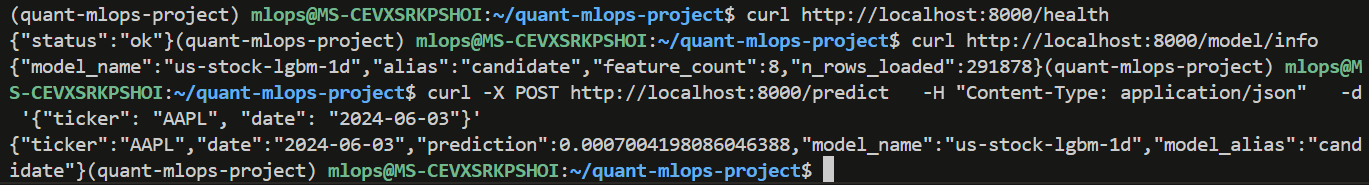